In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
TABLES_DIR = PROJECT_DIR / "results" / "tables"
FIGURES_DIR = PROJECT_DIR / "results" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

previous_results = pd.read_csv(
    TABLES_DIR / "network_resilience_comparison.csv"
)

display(previous_results.head())
print("Strategies:", previous_results["strategy"].unique())
print("Rows:", len(previous_results))

,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,remaining_nodes,strategy
0,0.00,0.0,986.0,0.981095,1005.0,Betweenness-based
1,0.05,50.0,896.0,0.891542,955.0,Betweenness-based
2,0.10,100.0,812.0,0.807960,905.0,Betweenness-based
3,0.15,151.0,726.0,0.722388,854.0,Betweenness-based
4,0.20,201.0,638.0,0.634826,804.0,Betweenness-based


Strategies: ['Betweenness-based' 'Degree-based' 'Department-aware'
 'Random (20-run average)']
Rows: 44


In [2]:
required_columns = {
    "removal_fraction",
    "largest_component_fraction",
    "strategy"
}

assert required_columns.issubset(previous_results.columns), (
    "Some required columns are missing."
)

assert previous_results["removal_fraction"].between(0, 0.5).all(), (
    "Removal fractions must be between 0 and 0.5."
)

assert previous_results["largest_component_fraction"].between(0, 1).all(), (
    "Largest component fractions must be between 0 and 1."
)

print("Basic validation passed.")

validation_summary = (
    previous_results.groupby("strategy")
    .agg(
        number_of_measurements=("removal_fraction", "nunique"),
        minimum_lcc_fraction=("largest_component_fraction", "min"),
        maximum_lcc_fraction=("largest_component_fraction", "max")
    )
    .reset_index()
)

display(validation_summary)

validation_summary.to_csv(
    TABLES_DIR / "simulation_validation_summary.csv",
    index=False
)

Basic validation passed.


,strategy,number_of_measurements,minimum_lcc_fraction,maximum_lcc_fraction
0,Betweenness-based,11,0.029851,0.981095
1,Degree-based,11,0.134328,0.981095
2,Department-aware,11,0.102488,0.981095
3,Random (20-run average),11,0.458657,0.981095


In [3]:
edges = pd.read_csv(PROCESSED_DIR / "email_edges_clean.csv")
departments = pd.read_csv(
    PROCESSED_DIR / "email_departments_clean.csv"
)

edges["source"] = edges["source"].astype(int)
edges["target"] = edges["target"].astype(int)
departments["node"] = departments["node"].astype(int)

department_map = departments.set_index("node")["department"].to_dict()

G = nx.Graph()
G.add_edges_from(
    edges[["source", "target"]].itertuples(index=False, name=None)
)
G.add_nodes_from(departments["node"])

nx.set_node_attributes(G, department_map, "department")

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")
print(f"Connected components: {nx.number_connected_components(G)}")

Nodes: 1005
Edges: 16706
Connected components: 20


In [4]:
REMOVAL_FRACTIONS = np.linspace(0, 0.50, 11)

def simulate_removal(graph, removal_order, fractions):
    original_n = graph.number_of_nodes()
    rows = []

    for fraction in fractions:
        k = int(round(fraction * original_n))
        removed = set(removal_order[:k])

        remaining = [
            node for node in graph.nodes()
            if node not in removed
        ]

        subgraph = graph.subgraph(remaining)

        if subgraph.number_of_nodes() == 0:
            lcc_size = 0
        else:
            lcc_size = max(
                len(component)
                for component in nx.connected_components(subgraph)
            )

        rows.append({
            "removal_fraction": fraction,
            "removed_nodes": k,
            "largest_component_size": lcc_size,
            "largest_component_fraction": lcc_size / original_n
        })

    return pd.DataFrame(rows)

In [5]:
N_RANDOM_RUNS = 100
nodes = list(G.nodes())
random_runs = []

for run in range(N_RANDOM_RUNS):
    rng = np.random.default_rng(2026 + run)
    removal_order = rng.permutation(nodes).tolist()

    trial = simulate_removal(
        G, removal_order, REMOVAL_FRACTIONS
    )
    trial["run"] = run + 1
    random_runs.append(trial)

random_all = pd.concat(random_runs, ignore_index=True)

random_all.to_csv(
    TABLES_DIR / "random_removal_100_trials.csv",
    index=False
)

print("Completed random trials:", N_RANDOM_RUNS)
display(random_all.head())

Completed random trials: 100


,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,run
0,0.00,0,986,0.981095,1
1,0.05,50,934,0.929353,1
2,0.10,100,883,0.878607,1
3,0.15,151,829,0.824876,1
4,0.20,201,775,0.771144,1


In [6]:
random_summary = (
    random_all.groupby("removal_fraction")
    .agg(
        mean_lcc=("largest_component_fraction", "mean"),
        std_lcc=("largest_component_fraction", "std"),
        lower_95=("largest_component_fraction",
                  lambda x: x.quantile(0.025)),
        upper_95=("largest_component_fraction",
                  lambda x: x.quantile(0.975))
    )
    .reset_index()
)

display(random_summary)

random_summary.to_csv(
    TABLES_DIR / "random_removal_uncertainty.csv",
    index=False
)

,removal_fraction,mean_lcc,std_lcc,lower_95,upper_95
0,0.00,0.981095,0.000000,0.981095,0.981095
1,0.05,0.927711,0.003064,0.920398,0.932338
2,0.10,0.874945,0.003757,0.867139,0.881592
3,0.15,0.821453,0.004172,0.813930,0.828856
4,0.20,0.768169,0.005155,0.758209,0.776642
5,0.25,0.716368,0.005258,0.704950,0.725373
6,0.30,0.663483,0.005356,0.652736,0.672687
7,0.35,0.611552,0.005650,0.600945,0.622935
8,0.40,0.560100,0.006006,0.549254,0.571144
9,0.45,0.509612,0.006390,0.496990,0.520920


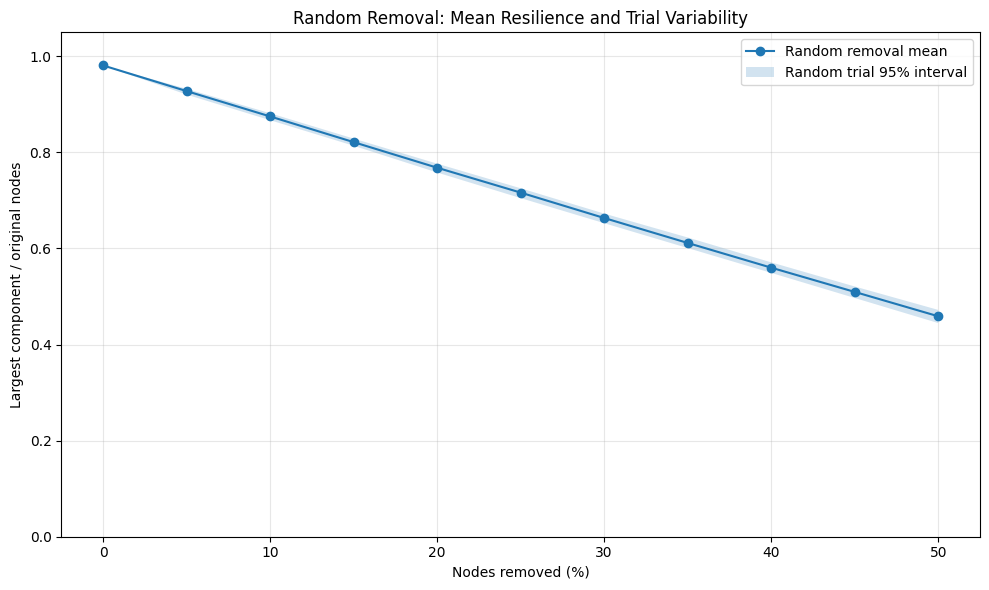

In [7]:
x = random_summary["removal_fraction"] * 100

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    random_summary["mean_lcc"],
    marker="o",
    label="Random removal mean"
)

plt.fill_between(
    x,
    random_summary["lower_95"],
    random_summary["upper_95"],
    alpha=0.2,
    label="Random trial 95% interval"
)

plt.xlabel("Nodes removed (%)")
plt.ylabel("Largest component / original nodes")
plt.title("Random Removal: Mean Resilience and Trial Variability")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "random_resilience_uncertainty.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
key_percentages = [0.10, 0.20, 0.30, 0.40, 0.50]

key_comparison = previous_results[
    previous_results["removal_fraction"].round(2).isin(key_percentages)
].copy()

key_comparison["removal_percent"] = (
    key_comparison["removal_fraction"] * 100
)

key_comparison = key_comparison[
    [
        "strategy",
        "removal_percent",
        "largest_component_fraction"
    ]
].sort_values(["removal_percent", "strategy"])

display(key_comparison)

key_comparison.to_csv(
    TABLES_DIR / "key_resilience_comparison.csv",
    index=False
)

,strategy,removal_percent,largest_component_fraction
2,Betweenness-based,10.0,0.807960
13,Degree-based,10.0,0.827861
24,Department-aware,10.0,0.811940
35,Random (20-run average),10.0,0.874776
4,Betweenness-based,20.0,0.634826
15,Degree-based,20.0,0.674627
26,Department-aware,20.0,0.652736
37,Random (20-run average),20.0,0.768955
6,Betweenness-based,30.0,0.498507
17,Degree-based,30.0,0.536318


**Re-evaluate the resilience AUC**

In [10]:
random_auc_rows = []

for run, group in random_all.groupby("run"):
    group = group.sort_values("removal_fraction")

    auc = np.trapezoid(
        group["largest_component_fraction"],
        group["removal_fraction"]
    )

    random_auc_rows.append({
        "run": run,
        "strategy": "Random",
        "resilience_auc": auc
    })

random_auc_df = pd.DataFrame(random_auc_rows)

targeted_auc_rows = []

for strategy, group in previous_results.groupby("strategy"):
    if strategy.startswith("Random"):
        continue

    group = group.sort_values("removal_fraction")

    auc = np.trapezoid(
        group["largest_component_fraction"],
        group["removal_fraction"]
    )

    targeted_auc_rows.append({
        "strategy": strategy,
        "resilience_auc": auc
    })

targeted_auc_df = pd.DataFrame(targeted_auc_rows)

random_auc_summary = pd.DataFrame([{
    "strategy": "Random",
    "mean_auc": random_auc_df["resilience_auc"].mean(),
    "std_auc": random_auc_df["resilience_auc"].std(),
    "lower_95": random_auc_df["resilience_auc"].quantile(0.025),
    "upper_95": random_auc_df["resilience_auc"].quantile(0.975)
}])

targeted_auc_summary = targeted_auc_df.rename(
    columns={"resilience_auc": "mean_auc"}
)
targeted_auc_summary["std_auc"] = np.nan
targeted_auc_summary["lower_95"] = np.nan
targeted_auc_summary["upper_95"] = np.nan

auc_comparison = pd.concat(
    [random_auc_summary, targeted_auc_summary],
    ignore_index=True
)

display(auc_comparison)

random_auc_df.to_csv(
    TABLES_DIR / "random_auc_100_trials.csv",
    index=False
)

auc_comparison.to_csv(
    TABLES_DIR / "validated_auc_comparison.csv",
    index=False
)

,strategy,mean_auc,std_auc,lower_95,upper_95
0,Random,0.358670,0.001946,0.3551,0.362132
1,Betweenness-based,0.281493,NaN,NaN,NaN
2,Degree-based,0.298632,NaN,NaN,NaN
3,Department-aware,0.283458,NaN,NaN,NaN


In [11]:
comparison = previous_results[
    previous_results["strategy"].isin([
        "Betweenness-based",
        "Department-aware"
    ])
].pivot(
    index="removal_fraction",
    columns="strategy",
    values="largest_component_fraction"
).reset_index()

comparison["department_aware_minus_betweenness"] = (
    comparison["Department-aware"]
    - comparison["Betweenness-based"]
)

display(comparison)

comparison.to_csv(
    TABLES_DIR / "department_vs_betweenness.csv",
    index=False
)

strategy,removal_fraction,Betweenness-based,Department-aware,department_aware_minus_betweenness
0,0.00,0.981095,0.981095,0.000000
1,0.05,0.891542,0.889552,-0.001990
2,0.10,0.807960,0.811940,0.003980
3,0.15,0.722388,0.730348,0.007960
4,0.20,0.634826,0.652736,0.017910
5,0.25,0.566169,0.576119,0.009950
6,0.30,0.498507,0.500498,0.001990
7,0.35,0.421891,0.417910,-0.003980
8,0.40,0.334328,0.327363,-0.006965
9,0.45,0.246766,0.220896,-0.025871
